**ANOMALY DETECTION OC-SVM**

In [9]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [19]:
def load_mdf(job_name):
    results_dir = f"/tmp/anomaly_results_mdf_{job_name}"
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_mdf_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df


punti = ["encoder", "pre_proj", "post_proj"]
versioni = ["v1", "v2", "v3"]

righe = []
dati = {}                                   # chiave: (versione, punto)

for v in versioni:
    for p in punti:
        job_name = f"{v}_{p}"
        try:
            results, df = load_mdf(job_name)
        except Exception as e:
            print(f"salto {job_name}: {e}")     # run non ancora fatto o artifact mancante
            continue

        dati[(v, p)] = (results, df)

        riga = {
            "versione": v,
            "punto": p,
            "componenti PCA": results["n_componenti"],
            "AUROC": results["auroc"],
        }
        for fascia, r in results["auroc_fasce"].items():
            riga[f"AUROC {fascia}"] = r["auroc"]
        riga["score normali"] = df[df.label == 0]["score"].mean()
        riga["score anomale"] = df[df.label == 1]["score"].mean()
        righe.append(riga)

confronto = pd.DataFrame(righe).set_index(["versione", "punto"])
confronto.round(3)

componenti PCA  AUROC  AUROC 0-5%  AUROC 5-20%  \
versione punto                                                       
v1       encoder               512  0.854       0.728        0.820   
         pre_proj             2048  0.708       0.602        0.659   
         post_proj             256  0.710       0.583        0.637   
v2       encoder               512  0.771       0.589        0.706   
         pre_proj             2048  0.575       0.561        0.563   
         post_proj             256  0.728       0.627        0.679   
v3       encoder               512  0.744       0.594        0.706   
         pre_proj             2048  0.722       0.530        0.626   
         post_proj             256  0.630       0.512        0.566   

                    AUROC 20-100%  score normali  score anomale  
versione punto                                                   
v1       encoder            0.924       -695.536      -1236.806  
         pre_proj           0.785    -236775.088    -365769.724  
         post_proj          0.816       -301.606       -399.565  
v2       encoder            0.885       -690.108       -988.282  
         pre_proj           0.590    -212837.325    -242470.525  
         post_proj          0.803       -323.183       -518.352  
v3       encoder            0.825       -686.733       -906.050  
         pre_proj           0.867    -215360.694    -373094.621  
         post_proj          0.723       -295.563       -331.735

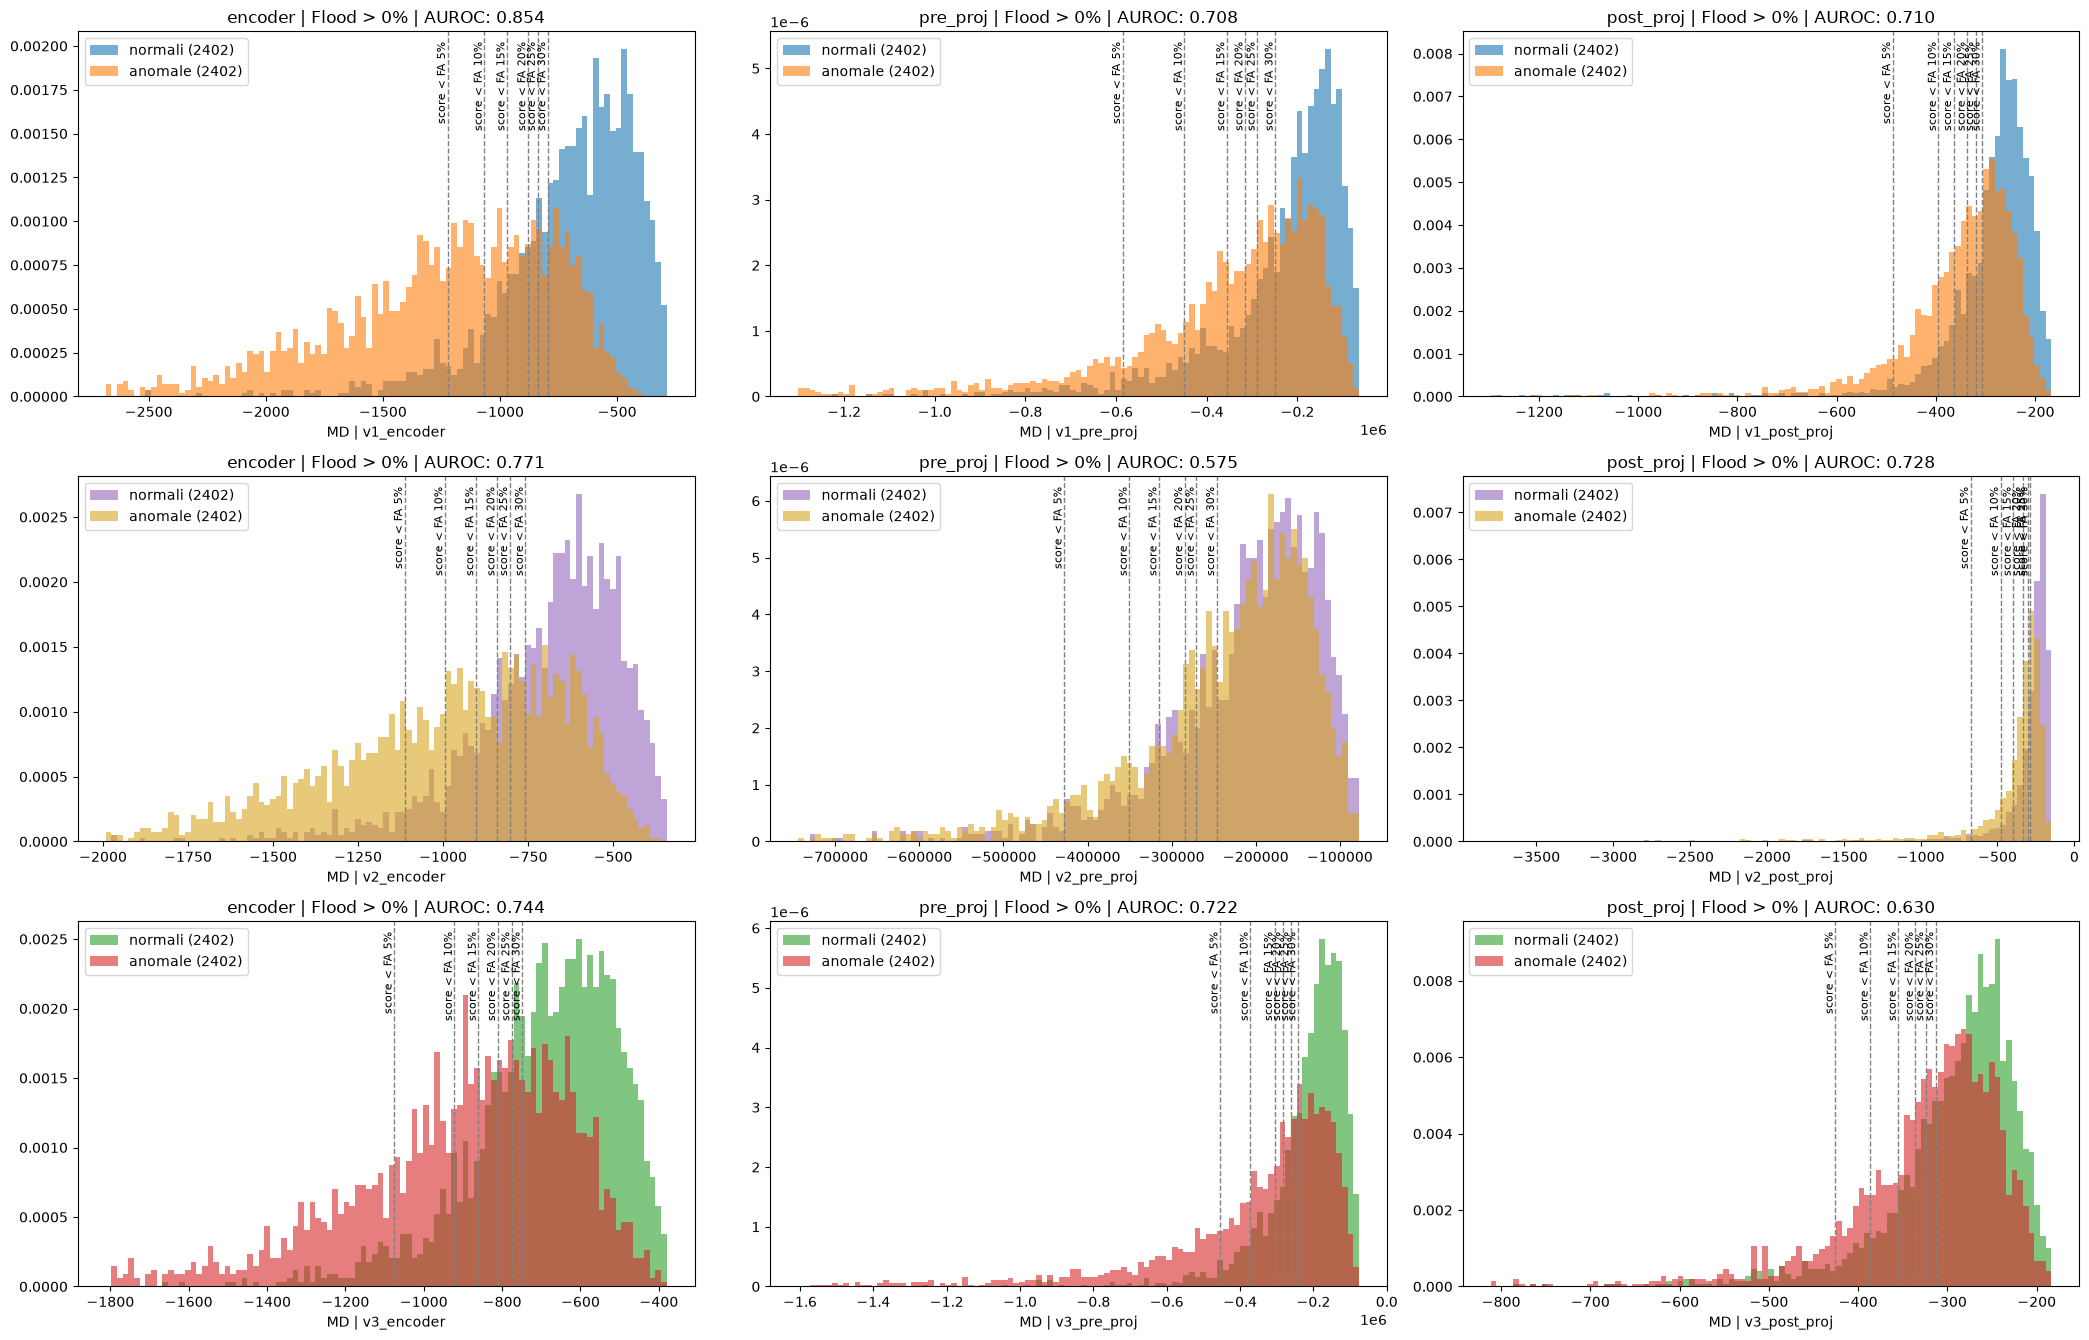

In [20]:
def plot_hist_mdf(ax, results, df, job_name, colori=("tab:blue", "tab:orange")):
    col_normal, col_anom = colori
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, color=col_normal, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, color=col_anom, label=f"anomale ({len(score_anom)})")

    for nome, r in results["rules"].items():
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)

    ax.set_xlabel(f"MD | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"{results['feature_point']} | Flood > {results['min_flood_area']:.0f}% | AUROC: {results['auroc']:.3f}")

colori_versione = {"v1": ("tab:blue", "tab:orange"), "v2": ("tab:purple", "goldenrod"), "v3": ("tab:green", "tab:red")}

fig, axes = plt.subplots(len(versioni), len(punti), figsize=(7 * len(punti), 4.5 * len(versioni)), squeeze=False)

for i, v in enumerate(versioni):
    for j, p in enumerate(punti):
        ax = axes[i, j]
        if (v, p) not in dati:              # combinazione non ancora calcolata
            ax.axis("off")
            continue
        results, df = dati[(v, p)]
        plot_hist_mdf(ax, results, df, job_name=f"{v}_{p}", colori=colori_versione[v])

plt.tight_layout()
plt.show()

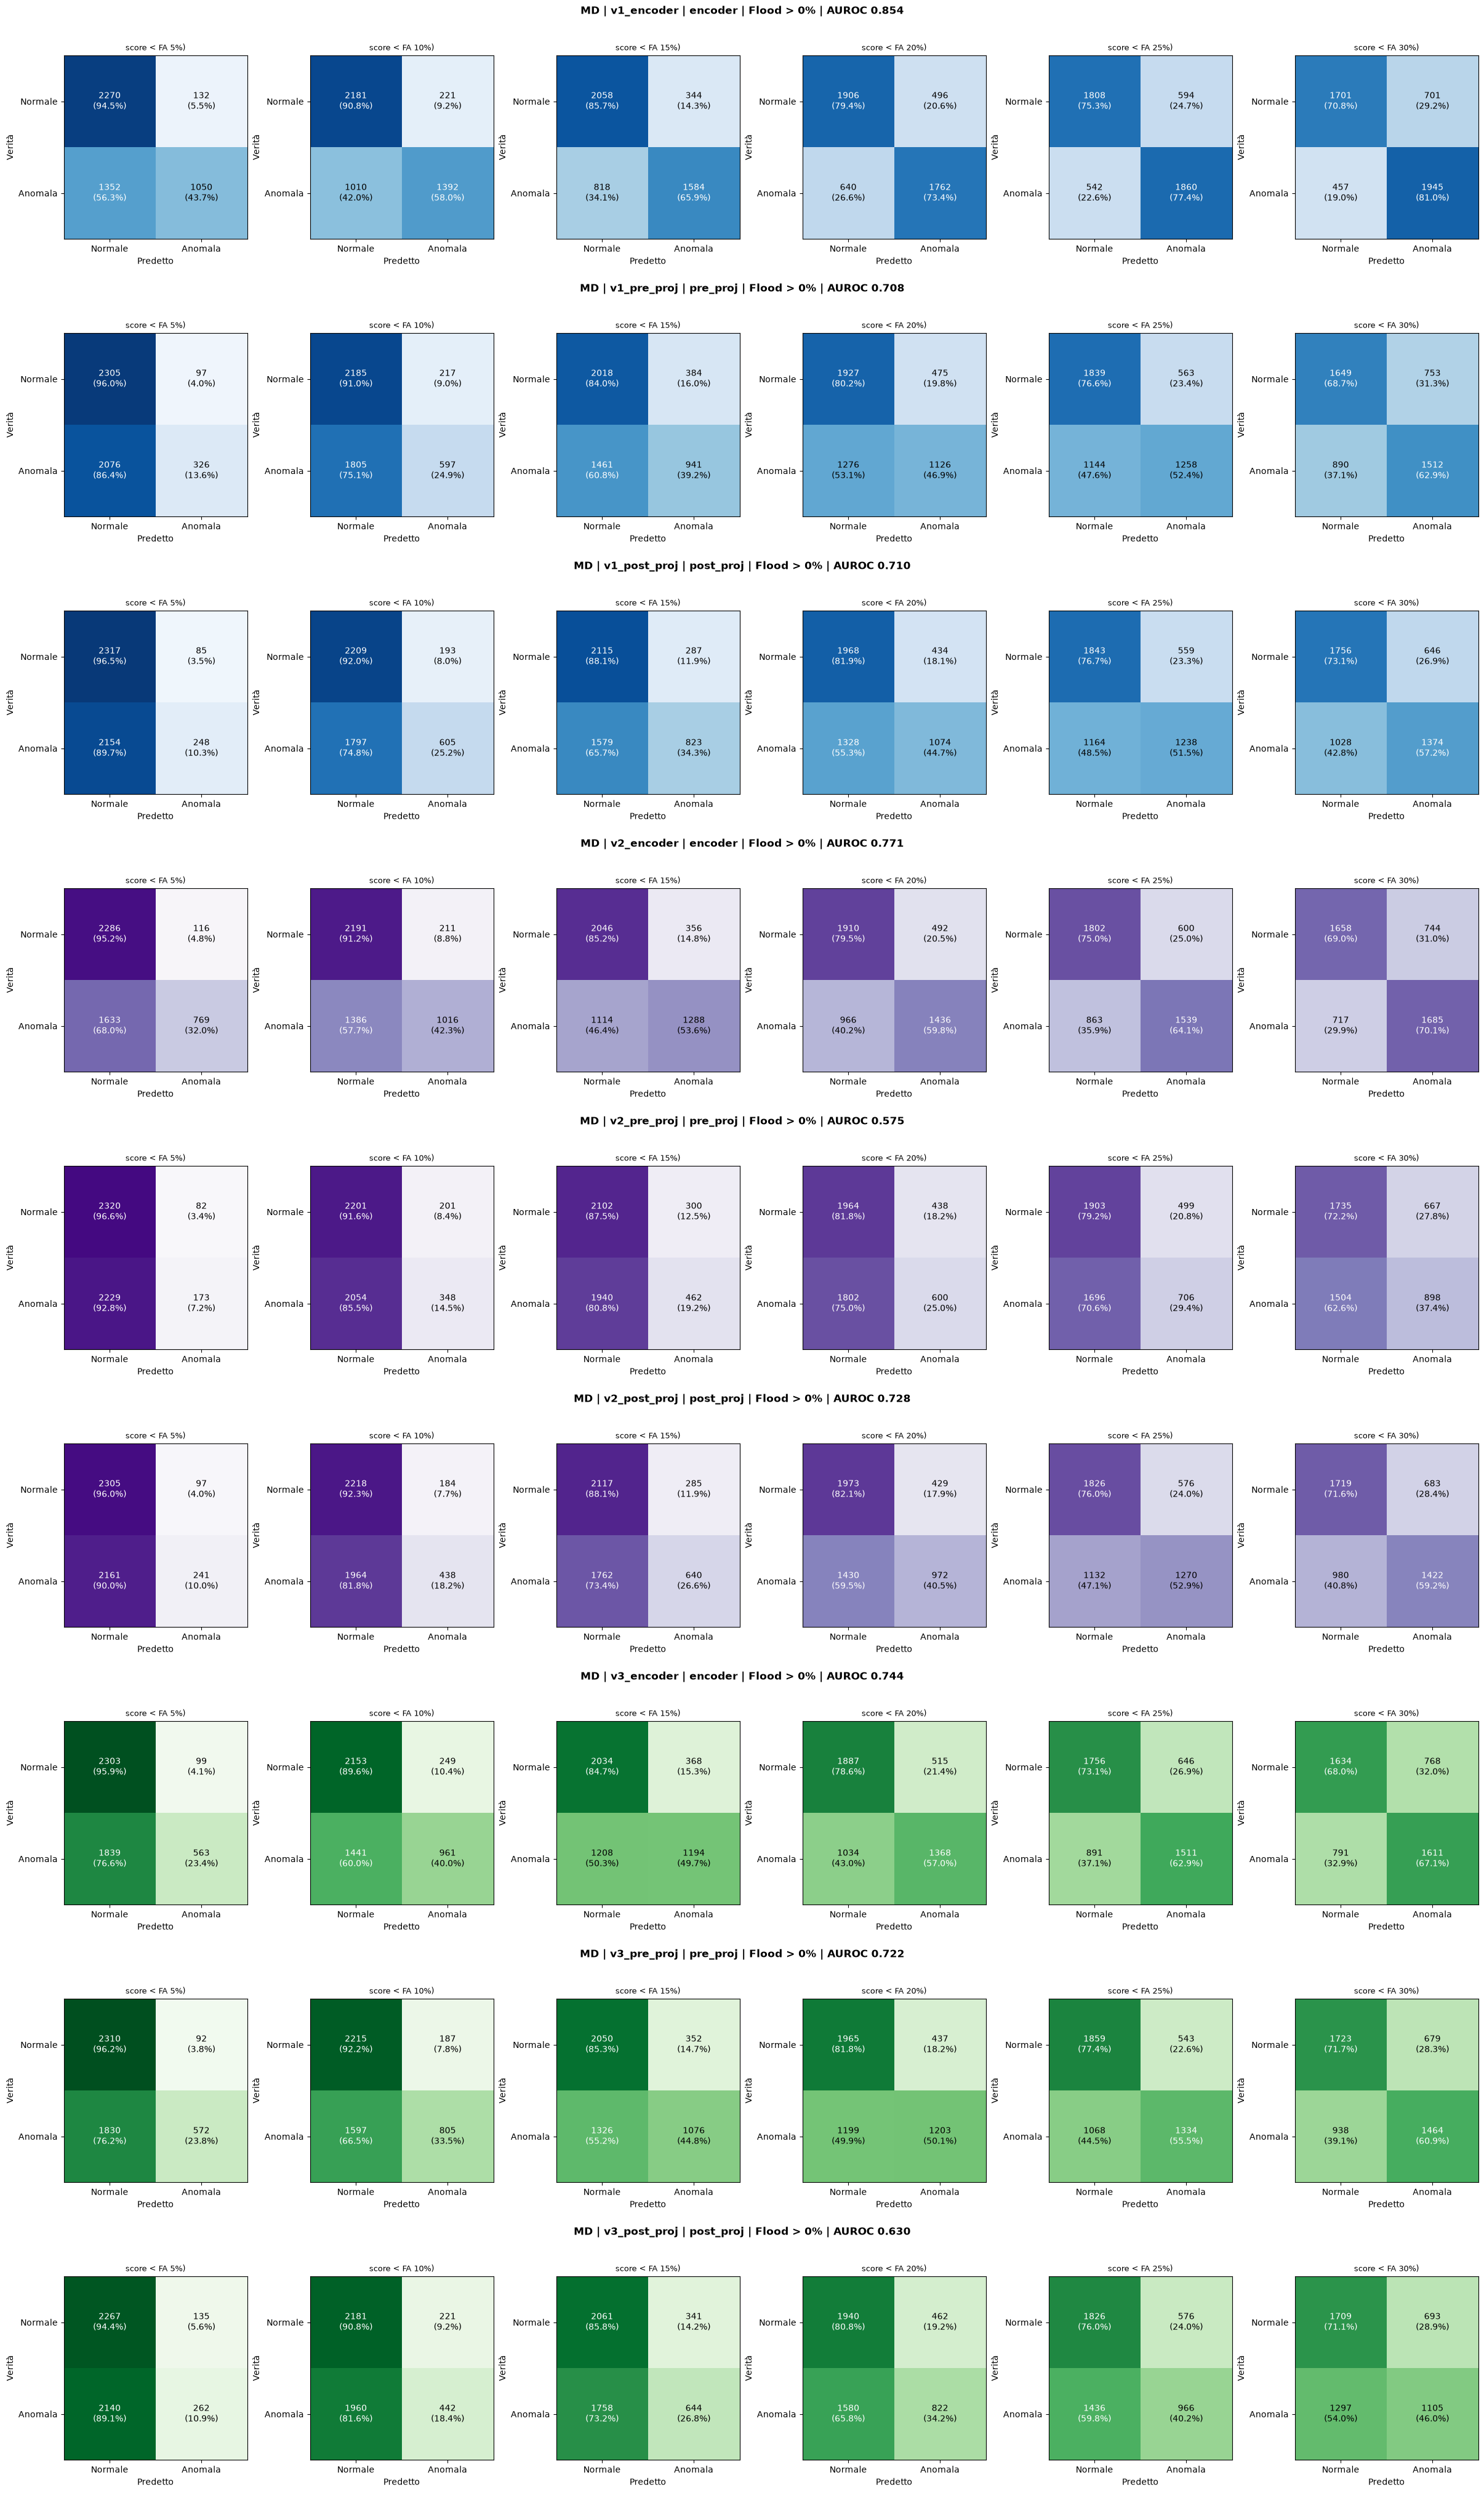

In [21]:
def plot_confusion_row(sfig, results, job_name, n_cols, cmap="Blues"):
    rules = results["rules"]
    axes_row = sfig.subplots(1, n_cols, squeeze=False)[0]

    for ax, (nome, r) in zip(axes_row, rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap=cmap, vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    for ax in axes_row[len(rules):]:
        ax.axis("off")

    sfig.suptitle(f"MD | {job_name} | {results['feature_point']} | Flood > {results['min_flood_area']:.0f}% | "
                  f"AUROC {results['auroc']:.3f}", fontsize=12, fontweight="bold")


cmap_versione = {"v1": "Blues", "v2": "Purples", "v3": "Greens"}

# combinazioni da mostrare, nell'ordine: prima per versione, poi per punto
combinazioni = [(v, p) for v in versioni for p in punti if (v, p) in dati]

# per vederne solo una parte, ad esempio un solo punto:
# combinazioni = [(v, p) for (v, p) in combinazioni if p == "encoder"]

n_rows = len(combinazioni)
n_cols = max(len(dati[c][0]["rules"]) for c in combinazioni)

fig = plt.figure(figsize=(4 * n_cols, 4.5 * n_rows), layout="constrained")
subfigs = np.atleast_1d(fig.subfigures(n_rows, 1))

for sfig, (v, p) in zip(subfigs, combinazioni):
    results, _ = dati[(v, p)]
    plot_confusion_row(sfig, results, job_name=f"{v}_{p}", n_cols=n_cols,
                       cmap=cmap_versione.get(v, "Blues"))

plt.show()